# 05 — SetFit-style contrastive fine-tuning

**CRISP-DM phase: Modelling, component 4a.** Until now the encoder was used as downloaded. Here it is fine-tuned on
the **130 fine-tune runs** so that cosine(description, trace) becomes *high for consistent* pairs and *low for
inconsistent* ones. Code: `src/embedding/finetune_setfit.py`.

**How it's trained.** SetFit trains its encoder with a contrastive `CosineSimilarityLoss` on sentence pairs. Our
examples already *are* pairs, so that objective is applied directly to each (description, trace text) pair:
consistent (NEG) → target cosine **1**, inconsistent (POS) → target cosine **0**. The encoder stays a bi-encoder, so
the score is still the same cosine as in notebooks 02–04. Report wording: *SetFit-style contrastive fine-tuning*.

**Rules fixed before running anything** (so no number below is chosen by looking at a result it's judged on):
- The **number of epochs** is picked by 5-fold cross-validation **inside the fine-tune split** (skill groups kept
  together). Learning rate is SetFit's default (2e-5), batch size 16.
- The pipeline uses the **enriched** text (the design). Flat text is trained the same way only as the **ablation**.
- The **saved** model is the one trained with seed 42, decided in advance; seeds 43 and 44 only measure variation.
- No swapped-description training pairs: Exp 5b uses those as a control.
- The **calibration split** (61 runs) is only used to *report* the effect here. The **test split stays locked.**

Stages:
1. Load the splits
2. What a training pair looks like
3. Pick the number of epochs (cross-validation inside fine-tune)
4. Train the final models (3 seeds) and look at the loss curve
5. Before vs after on the calibration split (fine-tuning delta, enrichment ablation)
6. Score distributions before vs after
7. By mode, and the empty-trace runs
8. Save the model and results

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # make src/ importable from notebooks/

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

from src.config import FINETUNED_EMBEDDING_DIR, RESULTS_DIR
from src.data.merge_labels import load_labelled_dataset
from src.embedding.encoder import Encoder
from src.embedding.finetune_setfit import cv_auc, finetune, pair_dataset, save, score
from src.embedding.similarity import consistency_scores
from src.preprocessing.trace_to_text import trace_to_enriched_text, trace_to_flat_text

BLUE, ORANGE = "#2a78d6", "#eb6834"
TEXTS = {"enriched": trace_to_enriched_text, "flat": trace_to_flat_text}
EPOCH_GRID = (1, 3, 5, 8, 12)
SEEDS = (42, 43, 44)          # 42 is the model that gets saved

ft = load_labelled_dataset(("finetune",))
cal = load_labelled_dataset(("calibration",))     # test is locked: never loaded
y_cal = np.array([r["label"] for r in cal])
print(f"fine-tune: {len(ft)} runs ({sum(r['label'] for r in ft)} POS)   calibration: {len(cal)} runs ({y_cal.sum()} POS)")

fine-tune: 130 runs (63 POS)   calibration: 61 runs (31 POS)


## 2. What a training pair looks like

In [2]:
pairs = pair_dataset(ft[:200]).to_pandas()
pairs["sentence1"] = pairs["sentence1"].str[:90]; pairs["sentence2"] = pairs["sentence2"].str[:110]
pd.set_option("display.max_colwidth", 120)
pd.concat([pairs[pairs.score == 1].head(2), pairs[pairs.score == 0].head(2)]).rename(
    columns={"sentence1": "description", "sentence2": "enriched trace", "score": "target cosine"})

,description,enriched trace,target cosine
0,"Guides Claude in managing authentication credentials including API keys, SSH keys, passwor","Reads its own skill files, then lists files, then writes temporary file credential_config.json, then runs Pyth",1.0
1,"Advanced UI/UX design system architecture. 50+ visual styles, 21 color palettes, 50 font p","Lists files, then reads its own skill files, then runs Python script search.py",1.0
3,AICash Network auto-miner for $CASH tokens on Base L2. Use when setting up automated Proof,"Reads its own skill files, then lists files, then searches for files, then opens a raw network connection to a",0.0
8,"Deep expertise in Solidity language features, patterns, and best practices for secure smar","Reads its own skill files, then lists files, then reads environment variables, then downloads from solidity-ru",0.0


## 3. Pick the number of epochs (cross-validation inside fine-tune)
For each candidate, the 130 fine-tune runs are split into 5 folds (skill groups never straddle folds): train on 4,
score the 5th, repeat, and average the AUC. The calibration split is not touched. *This is the slowest cell
(a few minutes per text type).*

Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

{'loss': 0.1613, 'grad_norm': 1.2557040452957153, 'learning_rate': 0.0, 'epoch': 0.14285714285714285}


{'loss': 0.2123, 'grad_norm': 1.701467752456665, 'learning_rate': 2e-05, 'epoch': 0.2857142857142857}


{'loss': 0.2883, 'grad_norm': 1.9940329790115356, 'learning_rate': 1.6666666666666667e-05, 'epoch': 0.42857142857142855}


{'loss': 0.3762, 'grad_norm': 2.671999454498291, 'learning_rate': 1.3333333333333333e-05, 'epoch': 0.5714285714285714}


...

{'loss': 0.0345, 'grad_norm': 0.77977055311203, 'learning_rate': 1.066666666666667e-06, 'epoch': 11.571428571428571}


{'loss': 0.06, 'grad_norm': 0.7943087816238403, 'learning_rate': 8.000000000000001e-07, 'epoch': 11.714285714285714}


{'loss': 0.0664, 'grad_norm': 0.8788094520568848, 'learning_rate': 5.333333333333335e-07, 'epoch': 11.857142857142858}


{'loss': 0.043, 'grad_norm': 1.0201722383499146, 'learning_rate': 2.666666666666667e-07, 'epoch': 12.0}
{'train_runtime': 3351.3791, 'train_samples_per_second': 0.372, 'train_steps_per_second': 0.025, 'train_loss': 0.11685904181961503, 'epoch': 12.0}


chosen epochs: {'enriched': 12, 'flat': 8}


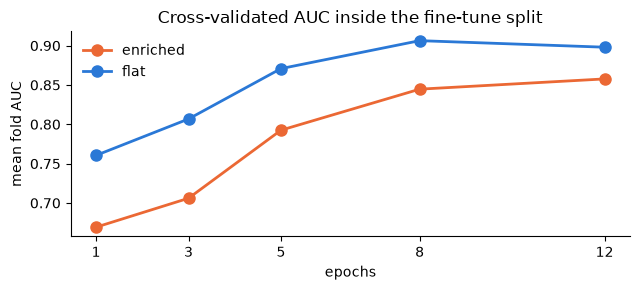

,enriched,flat
epochs,,
1,0.669,0.761
3,0.706,0.807
5,0.793,0.871
8,0.845,0.906
12,0.858,0.898


In [3]:
cv = pd.DataFrame({name: {e: cv_auc(ft, fn, epochs=e) for e in EPOCH_GRID} for name, fn in TEXTS.items()})
cv.index.name = "epochs"
best = {name: int(cv[name].idxmax()) for name in TEXTS}
print("chosen epochs:", best)

fig, ax = plt.subplots(figsize=(6.5, 3))
for name, color in [("enriched", ORANGE), ("flat", BLUE)]:
    ax.plot(cv.index, cv[name], marker="o", markersize=8, linewidth=2, color=color, label=name)
ax.set(title="Cross-validated AUC inside the fine-tune split", xlabel="epochs", ylabel="mean fold AUC", xticks=list(EPOCH_GRID))
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()
cv.round(3)

## 4. Train the final models (3 seeds) and look at the loss curve
Each final model is trained on **all 130** fine-tune runs with the chosen epochs. The loss is the mean squared gap
between the predicted cosine and its target (1 or 0); it should fall.

'(ProtocolError('Connection aborted.', RemoteDisconnected('Remote end closed connection without response')), '(Request ID: cef32f02-fb86-4985-b7d6-0882814f790f)')' thrown while requesting HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/./modules.json


Retrying in 1s [Retry 1/5].


Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

{'loss': 0.4575, 'grad_norm': 2.59710431098938, 'learning_rate': 0.0, 'epoch': 0.1111111111111111}


{'loss': 0.5008, 'grad_norm': 2.73016095161438, 'learning_rate': 1.8181818181818183e-06, 'epoch': 0.2222222222222222}


...

{'loss': 0.0846, 'grad_norm': 0.8157731890678406, 'learning_rate': 1.8750000000000003e-06, 'epoch': 7.444444444444445}


{'loss': 0.0757, 'grad_norm': 0.9034417271614075, 'learning_rate': 1.5625e-06, 'epoch': 7.555555555555555}


{'loss': 0.0842, 'grad_norm': 0.9461162090301514, 'learning_rate': 1.25e-06, 'epoch': 7.666666666666667}


{'loss': 0.0782, 'grad_norm': 1.0893234014511108, 'learning_rate': 9.375000000000001e-07, 'epoch': 7.777777777777778}


{'loss': 0.0605, 'grad_norm': 1.102705478668213, 'learning_rate': 6.25e-07, 'epoch': 7.888888888888889}
{'loss': 0.1039, 'grad_norm': 2.237156391143799, 'learning_rate': 3.125e-07, 'epoch': 8.0}
{'train_runtime': 3117.8203, 'train_samples_per_second': 0.334, 'train_steps_per_second': 0.023, 'train_loss': 0.1392594282903398, 'epoch': 8.0}


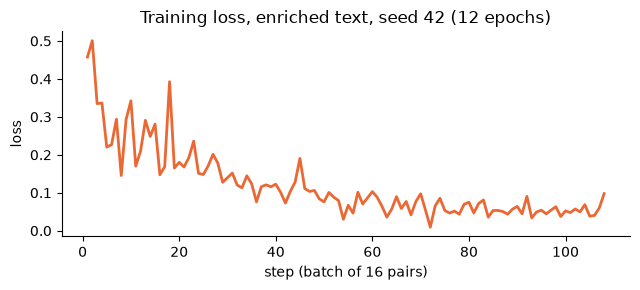

In [4]:
models, histories, cal_scores = {}, {}, {}
for name, fn in TEXTS.items():
    for seed in SEEDS:
        m, hist = finetune(ft, fn, epochs=best[name], seed=seed)
        models[(name, seed)], histories[(name, seed)] = m, hist
        cal_scores[(name, seed)] = score(m, cal, fn)

h = pd.DataFrame(histories[("enriched", 42)])
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.plot(h["step"], h["loss"], color=ORANGE, linewidth=2)
ax.set(title=f"Training loss, enriched text, seed 42 ({best['enriched']} epochs)", xlabel="step (batch of 16 pairs)", ylabel="loss")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## 5. Before vs after on the calibration split
**Pretrained** = notebooks 02/03. **Fine-tuned** = mean ± standard deviation over the 3 seeds. Two comparisons in one
table: the *fine-tuning delta* (Exp 2b preview) and *flat vs enriched after fine-tuning* (Exp 2 preview).

In [5]:
enc = Encoder()
D = enc.encode([r["description"] for r in cal])
rows_out = []
for name, fn in TEXTS.items():
    pre = roc_auc_score(y_cal, -consistency_scores(D, enc.encode([fn(r["trace"]) for r in cal])))
    post = [roc_auc_score(y_cal, -cal_scores[(name, s)]) for s in SEEDS]
    rows_out.append({"trace text": name, "pretrained AUC": pre, "fine-tuned AUC (mean)": np.mean(post),
                     "± sd over seeds": np.std(post), "delta": np.mean(post) - pre, "epochs": best[name]})
summary = pd.DataFrame(rows_out).set_index("trace text")
summary.round(3)

'(ProtocolError('Connection aborted.', RemoteDisconnected('Remote end closed connection without response')), '(Request ID: 945c9b0e-5cb0-4cfc-ac43-153c5d3d4a4b)')' thrown while requesting HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/./modules.json


Retrying in 1s [Retry 1/5].


,pretrained AUC,fine-tuned AUC (mean),± sd over seeds,delta,epochs
trace text,,,,,
enriched,0.602,0.768,0.004,0.166,12
flat,0.634,0.792,0.000,0.158,8


## 6. Score distributions before vs after (enriched, seed 42)
Fine-tuning should pull the two groups apart: consistent runs up, inconsistent runs down.

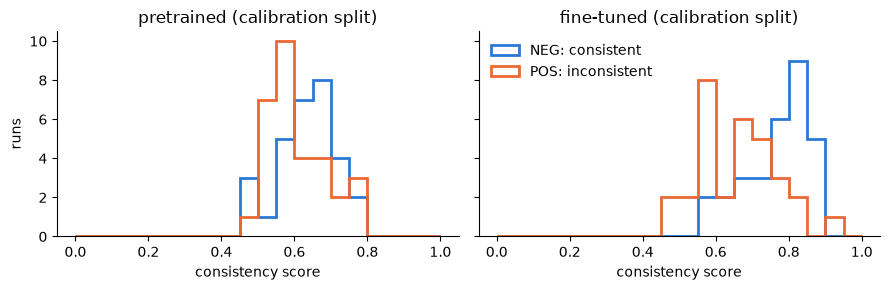

In [6]:
s_pre = consistency_scores(D, enc.encode([trace_to_enriched_text(r["trace"]) for r in cal]))
s_post = cal_scores[("enriched", 42)]
fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharey=True)
for ax, s, title in [(axes[0], s_pre, "pretrained"), (axes[1], s_post, "fine-tuned")]:
    bins = np.linspace(min(s.min(), 0), 1, 21)
    ax.hist(s[y_cal == 0], bins=bins, histtype="step", linewidth=2, color=BLUE, label="NEG: consistent")
    ax.hist(s[y_cal == 1], bins=bins, histtype="step", linewidth=2, color=ORANGE, label="POS: inconsistent")
    ax.set(title=f"{title} (calibration split)", xlabel="consistency score")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("runs"); axes[1].legend(frameon=False)
plt.tight_layout(); plt.show()

## 7. By mode, and the empty-trace runs
Only 61 calibration runs, so per-mode numbers are rough (a handful of runs each). A large gain in only one mode would
mean the model learned that mode's style rather than consistency.

In [7]:
modes = np.array([r["mode"] for r in cal])
empty = np.array([trace_to_enriched_text(r["trace"]) == "Does nothing observable" for r in cal])
by_mode = []
for m in ["agent", "direct", "instructed"]:
    k = modes == m
    ok = 0 < y_cal[k].sum() < k.sum()
    by_mode.append({"mode": m, "n": int(k.sum()), "POS": int(y_cal[k].sum()),
                    "pretrained AUC": roc_auc_score(y_cal[k], -s_pre[k]) if ok else np.nan,
                    "fine-tuned AUC": roc_auc_score(y_cal[k], -s_post[k]) if ok else np.nan})
print(pd.DataFrame(by_mode).round(3).to_string(index=False))
print(f"\nempty-trace runs in calibration: {empty.sum()} (all NEG)")
if empty.any():
    print(f"  mean score  pretrained {s_pre[empty].mean():.3f} -> fine-tuned {s_post[empty].mean():.3f}"
          f"   (other NEG after fine-tuning: {s_post[~empty & (y_cal == 0)].mean():.3f})")

      mode  n  POS  pretrained AUC  fine-tuned AUC
     agent 13    3           0.667           0.667
    direct 27   14           0.791           0.791
instructed 21   14           0.337           0.653

empty-trace runs in calibration: 4 (all NEG)
  mean score  pretrained 0.498 -> fine-tuned 0.730   (other NEG after fine-tuning: 0.770)


## 8. Save the model and results
The seed-42 enriched model goes to `models/finetuned_embedding/`; notebook 06 (calibration) and the evaluator load it
from there.

In [8]:
save(models[("enriched", 42)], FINETUNED_EMBEDDING_DIR)
RESULTS_DIR.mkdir(exist_ok=True)
cv.to_csv(RESULTS_DIR / "setfit_cv_epochs.csv")
summary.to_csv(RESULTS_DIR / "setfit_calibration_delta.csv")
pd.DataFrame({"sample_id": [r["sample_id"] for r in cal], "mode": modes, "label": y_cal,
              "score_pretrained": s_pre.round(4), "score_finetuned": s_post.round(4)}).to_csv(
    RESULTS_DIR / "setfit_calibration_scores.csv", index=False)
(RESULTS_DIR / "setfit_loss_enriched_seed42.json").write_text(json.dumps(histories[("enriched", 42)]))
print("saved model ->", FINETUNED_EMBEDDING_DIR)
print("saved results -> results/setfit_*.csv / .json")

saved model -> /Users/khawceline03/Desktop/Projects/School/Divergence/models/finetuned_embedding
saved results -> results/setfit_*.csv / .json


## What this shows
*(Read the numbers above; the text below is what to look for.)*
- **Fine-tuning delta (stage 5):** how much 130 labelled pairs improve the same cosine score. This is the
  Exp 2b question, previewed on the calibration split; the real answer comes from the locked test split.
- **Enrichment after fine-tuning (stage 5):** in notebook 03 enrichment did not help a *pretrained* encoder. If it
  now beats flat, that supports the claim that the named actions are learnable signal, not just shorter text.
- **Seed spread (stage 5):** with 130 examples, a delta smaller than the seed spread is not a real difference.
- **By mode (stage 7):** check the gain isn't coming from one mode only.

**Next:** `06_calibration.ipynb`: logistic regression on the calibration split, combining this score with the
three structural flags (and trace length, for the empty-trace runs) into the final verdict.